# Synthetic place-cell sanity check

Builds real and synthetic-train dataloaders for one session, then plots:
1. Empirical real rate map (no smoothing).
2. Smoothed model rate map (`PlaceCellSimulator3D.rate_map`).
3. Empirical synthetic rate map (recomputed from synthetic spikes).
4. Empirical synthetic_traj rate map (per-cluster rate maps, marginalized).

Plus per-neuron mean-rate and lag-1 autocorrelation scatters comparing
real vs each of the two synthetic variants.


In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from digitalbat.datasets.data import bat_data_loader
from digitalbat.datasets.defaults import make_data_config
from digitalbat.datasets.synthetic import (
    make_synthetic_train_dataloaders,
    make_synthetic_train_dataloaders_traj,
)

sns.set_context('notebook')
rng = np.random.default_rng(0)


In [2]:
sess_name = 'Dataset_3_14543_240419'
cfg = make_data_config(session_names=[sess_name])
real_dl, behavior_dim, unit_num_dict, meta = bat_data_loader(**cfg)
syn_dl, simulators = make_synthetic_train_dataloaders(
    real_dl, meta, dt=cfg['bin_width'], seed=0)
sim = simulators[sess_name]
syn_traj_dl, simulators_traj = make_synthetic_train_dataloaders_traj(
    real_dl, meta, dt=cfg['bin_width'], min_cluster_size=3, seed=0)
sim_traj = simulators_traj[sess_name]  # {cluster_id|'other' -> PlaceCellSimulator3D}
print(f'rate_map shape: {sim.rate_map.shape}')
print(f'synthetic_traj sub-simulators: {list(sim_traj.keys())}')


  Acceleration filter: removed 4/37 flights (peak |acc| > 40 m/s²)


rate_map shape: (289, 53, 44, 19)


In [3]:
# Pull arrays out of the train datasets and un-z-score positions.
real_ds = real_dl['train'][sess_name].dataset
syn_ds  = syn_dl['train'][sess_name].dataset
syn_traj_ds = syn_traj_dl['train'][sess_name].dataset
mask = real_ds.mask.numpy() == 1.0
bm = np.asarray(meta['behavior_mean'][sess_name]).reshape(-1)
bs = np.asarray(meta['behavior_std'][sess_name]).reshape(-1)
pos_xyz = (real_ds.behavior.numpy() * bs + bm)[..., :3]
real_spk = real_ds.spike.numpy()
syn_spk  = syn_ds.spike.numpy()
syn_traj_spk = syn_traj_ds.spike.numpy()

flat_pos = pos_xyz[mask]
flat_real_spk = real_spk[mask]
flat_syn_spk  = syn_spk[mask]
flat_syn_traj_spk = syn_traj_spk[mask]
print(f'n_valid_steps={mask.sum()}, n_neurons={flat_real_spk.shape[1]}')


n_valid_steps=795, n_neurons=289


In [4]:
# Helper: 2D (x,y) rate map by marginalizing z.  Returns rate in Hz/bin.
def empirical_xy_ratemap(positions, spikes, edges, dt):
    occ_3d, _ = np.histogramdd(positions, bins=edges)
    occ_xy = occ_3d.sum(axis=2) * dt
    spk_3d, _ = np.histogramdd(positions, bins=edges, weights=spikes)
    spk_xy = spk_3d.sum(axis=2)
    return spk_xy / (occ_xy + 1e-8)

def model_xy_ratemap(rate_map_3d, occupancy_3d_time):
    """Marginalize the smoothed model rate map over z, weighted by occupancy."""
    weighted = rate_map_3d * occupancy_3d_time
    occ_xy = occupancy_3d_time.sum(axis=2)
    return weighted.sum(axis=2) / (occ_xy + 1e-8)

# Reconstruct 3D occupancy time for the model-marginal rate map.
occ_3d, _ = np.histogramdd(flat_pos, bins=sim.edges)
occ_3d_time = occ_3d * cfg['bin_width']

top units: [  1 200 203 227  62  37]


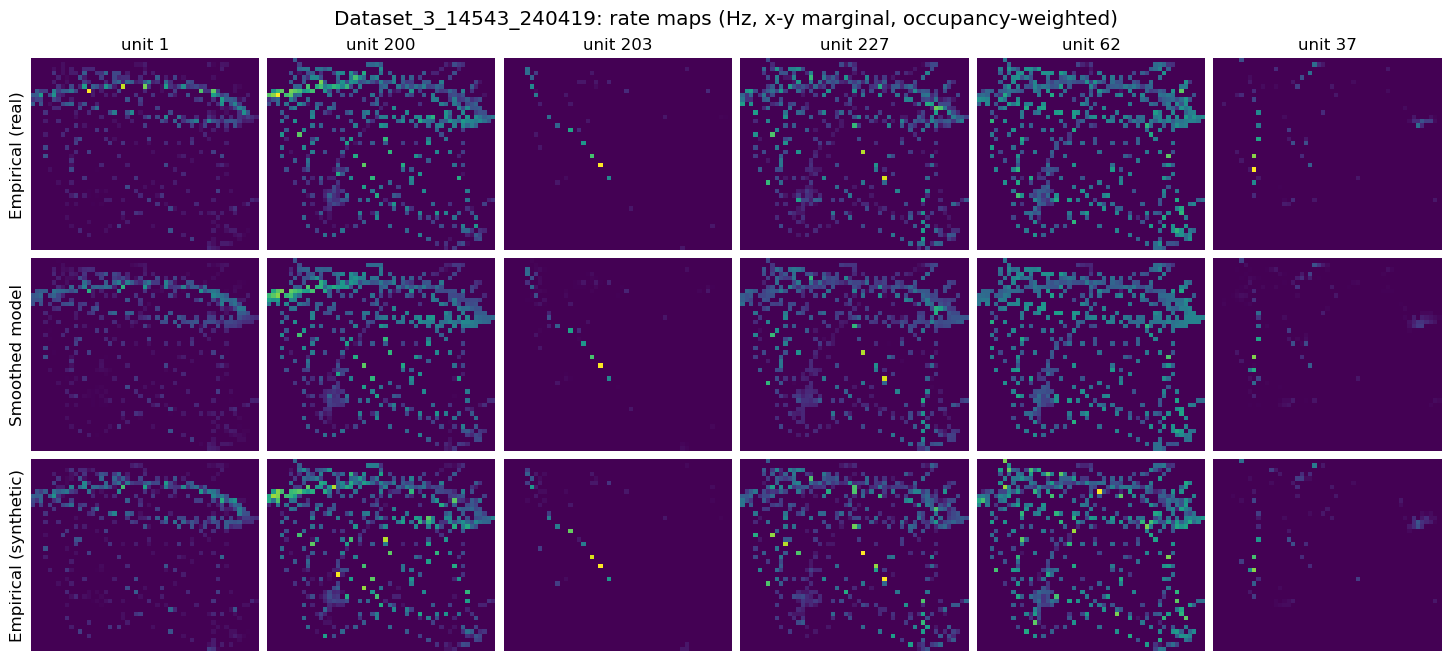

In [5]:
# Pick 6 neurons with the highest peak rate to plot (most place-cell-like).
peak_rate = sim.rate_map.reshape(sim.rate_map.shape[0], -1).max(axis=1)
top_units = np.argsort(peak_rate)[::-1][:6]
print(f'top units: {top_units}')

fig, axes = plt.subplots(4, len(top_units), figsize=(2.4 * len(top_units), 8.7),
                          constrained_layout=True)
extent = [sim.edges[0][0], sim.edges[0][-1], sim.edges[1][0], sim.edges[1][-1]]

for col, unit in enumerate(top_units):
    real_emp = empirical_xy_ratemap(flat_pos, flat_real_spk[:, unit], sim.edges, cfg['bin_width'])
    model_xy = model_xy_ratemap(sim.rate_map[unit], occ_3d_time)
    syn_emp = empirical_xy_ratemap(flat_pos, flat_syn_spk[:, unit], sim.edges, cfg['bin_width'])
    syn_traj_emp = empirical_xy_ratemap(flat_pos, flat_syn_traj_spk[:, unit], sim.edges, cfg['bin_width'])
    vmax = max(real_emp.max(), model_xy.max(), syn_emp.max(), syn_traj_emp.max())

    for row, (rm, label) in enumerate([
        (real_emp,     'Empirical (real)'),
        (model_xy,     'Smoothed model'),
        (syn_emp,      'Empirical (synthetic)'),
        (syn_traj_emp, 'Empirical (synthetic_traj)'),
    ]):
        ax = axes[row, col]
        sns.heatmap(rm.T, ax=ax, cmap='viridis', cbar=False, vmin=0, vmax=vmax,
                    xticklabels=False, yticklabels=False)
        ax.invert_yaxis()
        if row == 0:
            ax.set_title(f'unit {unit}')
        if col == 0:
            ax.set_ylabel(label)
fig.suptitle(f'{sess_name}: rate maps (Hz, x-y marginal, occupancy-weighted)')
plt.show()


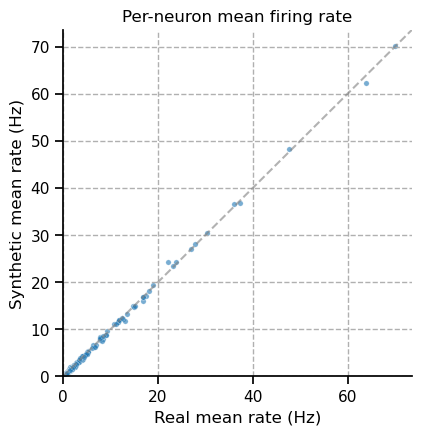

In [6]:
# Per-neuron mean firing rate, real vs synthetic.
real_mean_hz = flat_real_spk.mean(axis=0) / cfg['bin_width']
syn_mean_hz  = flat_syn_spk.mean(axis=0) / cfg['bin_width']
syn_traj_mean_hz = flat_syn_traj_spk.mean(axis=0) / cfg['bin_width']

fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.5))
lim = max(real_mean_hz.max(), syn_mean_hz.max(), syn_traj_mean_hz.max()) * 1.05
for ax, y_arr, label in zip(
    axes,
    [syn_mean_hz, syn_traj_mean_hz],
    ['synthetic (per-session rate map)', 'synthetic_traj (per-cluster rate map)'],
):
    ax.plot([0, lim], [0, lim], color='gray', linestyle='--', alpha=0.6)
    sns.scatterplot(x=real_mean_hz, y=y_arr, s=15, alpha=0.6, ax=ax)
    ax.set_xlabel('Real mean rate (Hz)')
    ax.set_ylabel(f'{label} mean rate (Hz)')
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
fig.suptitle('Per-neuron mean firing rate')
plt.tight_layout()
plt.show()


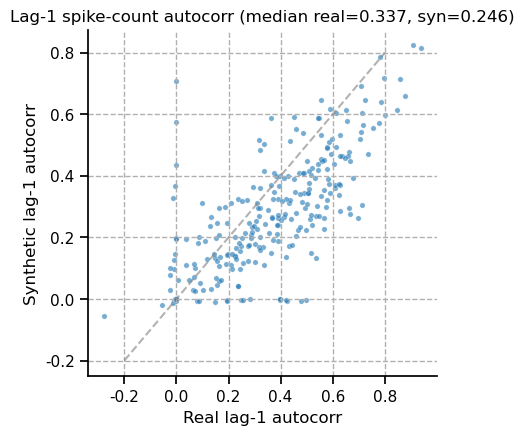

In [7]:
# Per-neuron lag-1 autocorrelation of binned spike counts, real vs each
# synthetic variant.  This is the diagnostic the experiment hinges on:
# synthetic spikes are Poisson-resampled per-timestep, so they should
# retain only the behavior-driven autocorrelation (positive when the bat
# sits in a place field) and lose any extra temporal structure.  The
# trajectory-specific variant adds within-cluster rate variation, so
# its autocorrelation should sit somewhere between real and synthetic.
def lag1_autocorr(spk, mask):
    out = np.zeros(spk.shape[-1])
    for k in range(spk.shape[-1]):
        xs, ys = [], []
        for i in range(spk.shape[0]):
            idx = np.where(mask[i])[0]
            if len(idx) < 2:
                continue
            contig = idx[1:][np.diff(idx) == 1]
            xs.append(spk[i, contig - 1, k])
            ys.append(spk[i, contig, k])
        xs = np.concatenate(xs); ys = np.concatenate(ys)
        if xs.std() > 0 and ys.std() > 0:
            out[k] = np.corrcoef(xs, ys)[0, 1]
    return out

real_ac = lag1_autocorr(real_spk, mask)
syn_ac  = lag1_autocorr(syn_spk, mask)
syn_traj_ac = lag1_autocorr(syn_traj_spk, mask)

fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.5))
for ax, y_arr, label in zip(
    axes,
    [syn_ac, syn_traj_ac],
    [f'synthetic (median={np.median(syn_ac):.3f})',
     f'synthetic_traj (median={np.median(syn_traj_ac):.3f})'],
):
    ax.plot([-0.2, 0.8], [-0.2, 0.8], color='gray', linestyle='--', alpha=0.6)
    sns.scatterplot(x=real_ac, y=y_arr, s=15, alpha=0.6, ax=ax)
    ax.set_xlabel(f'Real lag-1 autocorr (median={np.median(real_ac):.3f})')
    ax.set_ylabel(f'{label}')
fig.suptitle('Lag-1 spike-count autocorr')
plt.tight_layout()
plt.show()
